# Analyse rétrospective – Module C (Département R&D)

**Projet d'actuariat IMAFA 2026-2027 – Logiciel d'assurance de risque météorologique**

Pour une année passée $a$, un client $i$ et un niveau de pluie pivot $\overline{pl}$, on compare :

| Notation | Signification | Calcul |
|---|---|---|
| ${}^i_aR^{\overline{pl},nass}$ | résultat annuel du client **non assuré** | a posteriori |
| ${}^i_aP^{\overline{pl}}$ | prime annuelle payée au 1er janvier de $a$ | **a priori** (données avant $a$ uniquement) |
| ${}^i_aR^{\overline{pl},ass}$ | résultat annuel du client **assuré** (avant prime) | a posteriori |
| $R^{net} = R^{ass} - P$ | résultat assuré net de prime | |

Seule la récupération des pluies vient d'un autre module (`get_rainfall` du module A, `meteo_data.py`). Tous les calculs de la tâche C sont dans ce notebook.

Installation : `pip install requests pandas matplotlib`

In [1]:
%matplotlib inline
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from meteo_data import get_rainfall   # module A : pluie journalière d'une ville

pd.options.display.float_format = "{:,.0f}".format

N_ANNEES_HISTO = 30          # profondeur de l'historique servant à tarifer
PREMIERE_ANNEE_ERA5 = 1940   # début de l'archive Open-Meteo

19 jours >= 10 mm
date
1      19.0
2      15.0
3      16.0
4     160.0
5      74.0
6      22.0
7       4.0
8      30.0
9     105.0
10     71.0
11     34.0
12     35.0
Name: precip_mm, dtype: float64


## 1. Le modèle

Résultat journalier en fonction de la pluie $pl_t$ :

$$R_t = \begin{cases} CA - C_f & \text{si } pl_t = 0 \\ \dfrac{\overline{pl} - pl_t}{\overline{pl}}\, CA - C_f & \text{si } 0 < pl_t < \overline{pl} \\ -C_f & \text{si } pl_t \ge \overline{pl} \end{cases}$$

Le client est à perte dès que $pl_t > s$ avec le seuil $s = \overline{pl}\left(1 - \dfrac{C_f}{CA}\right)$.

L'assurance verse l'indemnité qui ramène le résultat à 0 :

$$I_t = \max(0, -R_t) = \min\left(C_f,\ \frac{CA}{\overline{pl}}\,(pl_t - s)^+\right)$$

donc $R^{ass}_t = R_t + I_t \ge 0$ chaque jour.

Les paramètres du client sont regroupés dans un dictionnaire `params` : `CA`, `Cf`, `pl_bar` (et `ville` pour la rétrospective).

In [2]:
def verifier(params: dict) -> tuple[float, float, float]:
    """Contrôle les paramètres du client et renvoie (CA, Cf, pl_bar)."""
    CA, Cf, pl_bar = float(params["CA"]), float(params["Cf"]), float(params["pl_bar"])
    if pl_bar <= 0:
        raise ValueError("Le pivot pl_bar doit être strictement positif.")
    if CA <= Cf:
        raise ValueError("Le sujet impose CA > Cf.")
    if Cf < 0:
        raise ValueError("Les coûts fixes doivent être positifs.")
    return CA, Cf, pl_bar


def seuil(params: dict) -> float:
    """Pluie au-delà de laquelle la journée est à perte : s = pl_bar (1 - Cf/CA)."""
    CA, Cf, pl_bar = verifier(params)
    return pl_bar * (1 - Cf / CA)


def resultat_journalier(pl, params: dict) -> np.ndarray:
    """R_t : CA - Cf si pas de pluie, f_t·CA - Cf si un peu, -Cf si pl_t >= pl_bar."""
    CA, Cf, pl_bar = verifier(params)
    pl = np.asarray(pl, dtype=float)
    f = np.clip((pl_bar - pl) / pl_bar, 0.0, 1.0)   # vaut 1 si pl = 0, 0 si pl >= pl_bar
    return f * CA - Cf


def indemnite(pl, params: dict) -> np.ndarray:
    """I_t = max(0, -R_t) : ramène le résultat du jour à 0."""
    return np.maximum(0.0, -resultat_journalier(pl, params))

In [3]:
params_test = {"CA": 1000, "Cf": 300, "pl_bar": 10}
pluies = np.array([0, 2, 5, 7, 8.5, 10, 30])
pd.DataFrame({
    "pluie (mm)": pluies,
    "R_t non assuré (€)": resultat_journalier(pluies, params_test),
    "indemnité I_t (€)": indemnite(pluies, params_test),
    "R_t assuré (€)": resultat_journalier(pluies, params_test) + indemnite(pluies, params_test),
}).style.format(precision=1)

,pluie (mm),R_t non assuré (€),indemnité I_t (€),R_t assuré (€)
0,0.0,700.0,0.0,700.0
1,2.0,500.0,0.0,500.0
2,5.0,200.0,0.0,200.0
3,7.0,0.0,-0.0,0.0
4,8.5,-150.0,150.0,0.0
5,10.0,-300.0,300.0,0.0
6,30.0,-300.0,300.0,0.0


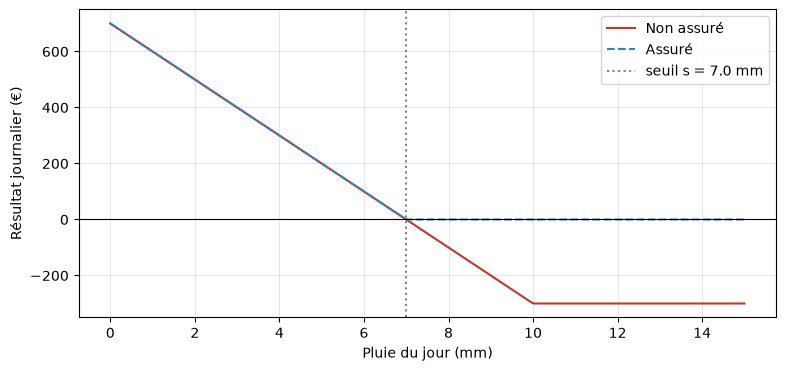

In [4]:
pl = np.linspace(0, 15, 300)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(pl, resultat_journalier(pl, params_test), label="Non assuré", color="#c0392b")
ax.plot(pl, resultat_journalier(pl, params_test) + indemnite(pl, params_test),
        label="Assuré", color="#2e86c1", ls="--")
ax.axhline(0, color="k", lw=0.8)
ax.axvline(seuil(params_test), color="grey", ls=":", label=f"seuil s = {seuil(params_test):.1f} mm")
ax.set_xlabel("Pluie du jour (mm)"); ax.set_ylabel("Résultat journalier (€)")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 2. La prime

La prime est la somme sur les 365 jours couverts de $E[I_t]$, estimée sur l'historique de la ville.

**Prime provisoire, en attendant le module B.** Pour chaque jour couvert, $E[I_t]$ est la moyenne des indemnités historiques des jours calendaires situés à ± 15 jours (effet de saison). C'est une prime pure, sans chargement.

Si le fichier `pricing.py` du module B est présent, sa fonction `price(params, historique)` est utilisée à la place.

In [5]:
def prime_empirique(params: dict, historique: pd.DataFrame,
                    debut: date | None = None, fenetre: int = 15) -> float:
    """Prime pure : somme sur 365 jours de la moyenne des indemnités à ± fenetre jours."""
    histo = historique.dropna(subset=["precip_mm"])
    if histo.empty:
        raise ValueError("Historique vide : impossible de tarifer.")
    debut = pd.Timestamp(debut or params.get("date_souscription") or date.today())
    jours_couverts = pd.date_range(debut, periods=365, freq="D")

    ind = indemnite(histo["precip_mm"].to_numpy(), params)
    doy_histo = histo["date"].dt.day_of_year.clip(upper=365).to_numpy()
    # moyenne par jour de l'année, lissée sur une fenêtre circulaire de ± fenetre jours
    somme = np.bincount(doy_histo - 1, weights=ind, minlength=365)
    compte = np.bincount(doy_histo - 1, minlength=365)
    noyau = np.ones(2 * fenetre + 1)
    somme_f = np.convolve(np.concatenate([somme[-fenetre:], somme, somme[:fenetre]]), noyau, "valid")
    compte_f = np.convolve(np.concatenate([compte[-fenetre:], compte, compte[:fenetre]]), noyau, "valid")
    esperance = somme_f / np.maximum(compte_f, 1)

    doy_couverts = jours_couverts.day_of_year.to_numpy().clip(max=365)
    return float(esperance[doy_couverts - 1].sum())


try:  # module B, s'il est présent dans le dépôt
    from pricing import price
    print("Prime : module B (pricing.price)")
except ImportError:
    price = prime_empirique
    print("Prime : méthode empirique provisoire (module B absent)")

Prime : méthode empirique provisoire (module B absent)


## 3. Fonctions de la rétrospective

- `backtest(params, annee)` : une année complète (1er janvier → 31 décembre).
- `backtest_periode(params, debut, fin)` : une ligne par année, une seule requête météo.

**Règle anti-biais** : la prime de l'année $a$ est calculée uniquement avec les pluies strictement antérieures au 1er janvier de $a$.

In [6]:
def backtest(params: dict, annee: int, n_annees_histo: int = N_ANNEES_HISTO,
             pluie_annee: pd.DataFrame | None = None,
             historique: pd.DataFrame | None = None,
             price_fn=None) -> dict:
    """
    Analyse rétrospective d'une année complète.
    pluie_annee / historique : à passer pour éviter les appels réseau.
    price_fn(params, historique) : fonction de tarification (price par défaut).
    """
    verifier(params)
    annee = int(annee)
    if annee >= date.today().year:
        raise ValueError("L'année doit être entièrement passée.")
    if annee <= PREMIERE_ANNEE_ERA5:
        raise ValueError(f"Pas d'historique avant {PREMIERE_ANNEE_ERA5}.")
    ville = params["ville"]
    debut_a, fin_a = date(annee, 1, 1), date(annee, 12, 31)

    # a priori : historique strictement avant le 1er janvier de a
    if historique is None:
        debut_h = date(max(annee - n_annees_histo, PREMIERE_ANNEE_ERA5), 1, 1)
        historique = get_rainfall(ville, debut_h, date(annee - 1, 12, 31))
    historique = historique[historique["date"] < pd.Timestamp(debut_a)]
    params_a = {**params, "date_souscription": debut_a}
    prime = float((price_fn or price)(params_a, historique))

    # a posteriori : pluie réellement tombée pendant l'année a
    if pluie_annee is None:
        pluie_annee = get_rainfall(ville, debut_a, fin_a)
    jours = pluie_annee[["date", "precip_mm"]].copy()
    manquants = int(jours["precip_mm"].isna().sum())
    jours["precip_mm"] = jours["precip_mm"].fillna(0.0)
    jours["R_nass"] = resultat_journalier(jours["precip_mm"], params)
    jours["indemnite"] = indemnite(jours["precip_mm"], params)
    jours["R_ass"] = jours["R_nass"] + jours["indemnite"]

    R_nass = float(jours["R_nass"].sum())
    R_ass = float(jours["R_ass"].sum())
    pertes_evitees = R_ass - R_nass
    return {
        "ville": ville,
        "annee": annee,
        "params": dict(params),
        "seuil": seuil(params),
        "P": prime,
        "R_nass": R_nass,
        "R_ass": R_ass,
        "R_net": R_ass - prime,
        "pertes_evitees": pertes_evitees,       # = somme des indemnités versées
        "gain_assurance": pertes_evitees - prime,
        "favorable": pertes_evitees > prime,
        "jours_a_perte": int((jours["indemnite"] > 0).sum()),
        "jours_manquants": manquants,
        "annees_histo": historique["date"].dt.year.nunique(),
        "jours": jours,
    }


def resume(res: dict) -> str:
    """Texte de synthèse dans l'esprit de l'exemple du sujet."""
    e = lambda x: f"{x:,.0f} €".replace(",", " ")
    p = res["params"]
    verdict = "favorable" if res["favorable"] else "défavorable"
    return (
        f"{res['ville']} {res['annee']} | CA={e(p['CA'])}, Cf={e(p['Cf'])}, "
        f"pivot={p['pl_bar']} mm, seuil de perte={res['seuil']:.2f} mm\n"
        f"  Résultat non assuré (a posteriori)       : {e(res['R_nass'])}\n"
        f"  Prime calculée au 1er janvier (a priori) : {e(res['P'])}  "
        f"[{res['annees_histo']} années d'historique]\n"
        f"  Résultat assuré avant prime              : {e(res['R_ass'])}\n"
        f"  Résultat assuré net de prime             : {e(res['R_net'])}\n"
        f"  Pertes évitées {e(res['pertes_evitees'])} sur {res['jours_a_perte']} jours "
        f"vs prime {e(res['P'])} -> s'assurer aurait été {verdict} "
        f"({e(res['gain_assurance'])})."
    )


def backtest_periode(params: dict, debut: int, fin: int,
                     n_annees_histo: int = N_ANNEES_HISTO, price_fn=None) -> pd.DataFrame:
    """Une ligne par année ; une seule requête météo pour toute la période."""
    ville = params["ville"]
    debut_h = date(max(debut - n_annees_histo, PREMIERE_ANNEE_ERA5), 1, 1)
    pluie = get_rainfall(ville, debut_h, date(fin, 12, 31))
    lignes = []
    for a in range(debut, fin + 1):
        borne_h = pd.Timestamp(max(a - n_annees_histo, PREMIERE_ANNEE_ERA5), 1, 1)
        histo = pluie[(pluie["date"] >= borne_h) & (pluie["date"] < pd.Timestamp(a, 1, 1))]
        pluie_a = pluie[pluie["date"].dt.year == a]
        res = backtest(params, a, n_annees_histo, pluie_a, histo, price_fn)
        lignes.append({k: v for k, v in res.items() if k not in ("jours", "params")})
    return pd.DataFrame(lignes)

In [7]:
COULEURS = {"nass": "#c0392b", "ass": "#2e86c1", "net": "#1e8449", "prime": "#7f8c8d"}


def graphique_annee(res: dict):
    """Cumul du résultat sur l'année + barres de comparaison R_nass / P / R_ass / R_net."""
    j = res["jours"]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2, 1]})
    ax1.plot(j["date"], j["R_nass"].cumsum(), color=COULEURS["nass"], label="Non assuré")
    ax1.plot(j["date"], j["R_ass"].cumsum(), color=COULEURS["ass"], label="Assuré (avant prime)")
    ax1.plot(j["date"], j["R_ass"].cumsum() - res["P"], color=COULEURS["net"],
             ls="--", label="Assuré, net de prime")
    jours_perte = j[j["indemnite"] > 0]
    ax1.scatter(jours_perte["date"], j["R_nass"].cumsum()[jours_perte.index],
                s=12, color=COULEURS["nass"], zorder=3, label="Jour à perte")
    ax1.set_title(f"Résultat cumulé – {res['ville']} {res['annee']}")
    ax1.set_ylabel("€")
    ax1.grid(alpha=0.3)
    ax1.legend()

    noms = ["R non assuré", "Prime P", "R assuré", "R assuré net"]
    valeurs = [res["R_nass"], res["P"], res["R_ass"], res["R_net"]]
    couleurs = [COULEURS["nass"], COULEURS["prime"], COULEURS["ass"], COULEURS["net"]]
    barres = ax2.bar(noms, valeurs, color=couleurs)
    ax2.bar_label(barres, labels=[f"{v:,.0f} €".replace(",", " ") for v in valeurs], fontsize=8)
    ax2.set_title("Favorable" if res["favorable"] else "Défavorable",
                  color=COULEURS["net"] if res["favorable"] else COULEURS["nass"])
    ax2.tick_params(axis="x", rotation=20)
    ax2.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    return fig


def graphique_periode(df: pd.DataFrame):
    """Par année : prime a priori vs pertes évitées a posteriori."""
    fig, ax = plt.subplots(figsize=(12, 5))
    x = np.arange(len(df))
    ax.bar(x - 0.2, df["P"], width=0.4, color=COULEURS["prime"], label="Prime (a priori)")
    ax.bar(x + 0.2, df["pertes_evitees"], width=0.4, color=COULEURS["ass"],
           label="Pertes évitées (a posteriori)")
    ax.set_xticks(x, df["annee"], rotation=45)
    ax.set_ylabel("€")
    taux = df["pertes_evitees"].sum() / df["P"].sum()
    ax.set_title(f"{df['ville'].iloc[0]} : prime vs indemnités, {df['annee'].min()}-{df['annee'].max()} "
                 f"(indemnités / primes = {taux:.0%})")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    return fig

## 4. Paramètres du client et de l'analyse

Modifiez cette cellule puis relancez la suite du notebook.

In [8]:
client = {
    "CA": 1000,       # chiffre d'affaires journalier maximum (€)
    "Cf": 300,        # coûts fixes journaliers (€)
    "pl_bar": 10,     # niveau de pluie journalier pivot (mm)
    "ville": "Nice",
}
annee = 1998          # année analysée (n'importe quelle année passée, > 1940)
n_annees_histo = 30   # nombre d'années avant 'annee' utilisées pour tarifer
print(f"Seuil de perte : {seuil(client):.2f} mm")

Seuil de perte : 7.00 mm


## 5. Rétrospective sur l'année choisie

Les pluies sont téléchargées depuis Open-Meteo (archive ERA5) par le module A. La prime est calculée **uniquement** avec les années $a - 30$ à $a - 1$.

In [9]:
res = backtest(client, annee, n_annees_histo=n_annees_histo)
print(resume(res))
assert (res["jours"]["R_ass"] >= -1e-9).all(), "Le résultat assuré doit être >= 0 chaque jour"


Nice 1998 | CA=1 000 €, Cf=300 €, pivot=10 mm, seuil de perte=7.00 mm
  Résultat non assuré (a posteriori)       : 214 510 €
  Prime calculée au 1er janvier (a priori) : 9 224 €  [30 années d'historique]
  Résultat assuré avant prime              : 220 490 €
  Résultat assuré net de prime             : 211 266 €
  Pertes évitées 5 980 € sur 23 jours vs prime 9 224 € -> s'assurer aurait été défavorable (-3 244 €).


In [10]:
pd.Series({
    "R non assuré (a posteriori)": res["R_nass"],
    "Prime P (a priori)": res["P"],
    "R assuré avant prime": res["R_ass"],
    "R assuré net de prime": res["R_net"],
    "Pertes évitées (indemnités)": res["pertes_evitees"],
    "Gain de l'assurance (pertes évitées - P)": res["gain_assurance"],
}, name=f"{client['ville']} {annee} (€)").to_frame()

,Nice 1998 (€)
R non assuré (a posteriori),"214,510"
Prime P (a priori),"9,224"
R assuré avant prime,"220,490"
R assuré net de prime,"211,266"
Pertes évitées (indemnités),"5,980"
Gain de l'assurance (pertes évitées - P),"-3,244"


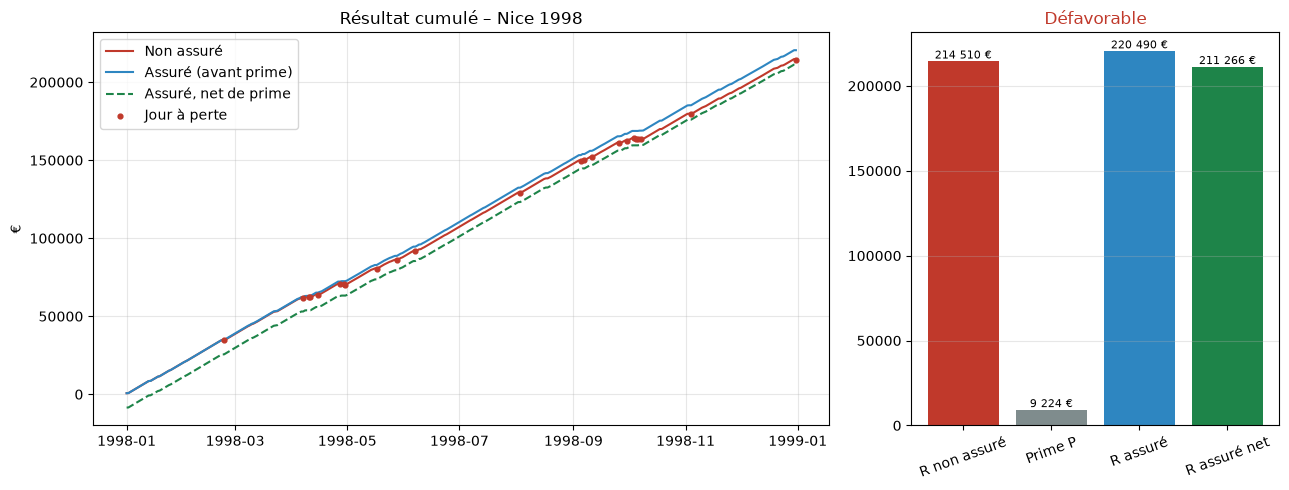

In [11]:
graphique_annee(res)
plt.show()

### Détail des jours à perte

In [12]:
jours = res["jours"]
jours_perte = jours[jours["indemnite"] > 0]
print(f"{len(jours_perte)} jours à perte, {res['jours_manquants']} jours sans donnée")
jours_perte.style.format({"precip_mm": "{:.1f}", "R_nass": "{:,.0f}", "indemnite": "{:,.0f}", "R_ass": "{:,.0f}"}).hide(axis="index")

23 jours à perte, 0 jours sans donnée


date,precip_mm,R_nass,indemnite,R_ass
1998-02-23 00:00:00,11.7,-300,300,0
1998-04-07 00:00:00,12.1,-300,300,0
1998-04-10 00:00:00,20.7,-300,300,0
1998-04-11 00:00:00,7.7,-70,70,0
1998-04-15 00:00:00,20.9,-300,300,0
1998-04-27 00:00:00,19.5,-300,300,0
1998-04-29 00:00:00,14.5,-300,300,0
1998-04-30 00:00:00,44.5,-300,300,0
1998-05-17 00:00:00,10.7,-300,300,0
1998-05-28 00:00:00,40.4,-300,300,0


In [13]:
mensuel = jours.groupby(jours["date"].dt.month).agg(
    pluie_mm=("precip_mm", "sum"),
    jours_a_perte=("indemnite", lambda x: (x > 0).sum()),
    indemnites=("indemnite", "sum"),
    R_nass=("R_nass", "sum"),
)
mensuel.index.name = "mois"
mensuel

,pluie_mm,jours_a_perte,indemnites,R_nass
mois,,,,
1,19,0,0,"19,750"
2,15,1,300,"18,250"
3,16,0,0,"20,130"
4,160,7,"1,870","12,180"
5,74,2,600,"17,440"
6,22,1,300,"18,900"
7,4,0,0,"21,280"
8,30,1,300,"19,190"
9,105,5,"1,230","15,160"


## 6. Rétrospective sur plusieurs années

Une seule année ne suffit pas pour juger la prime : on refait le test pour chaque année d'une période, toujours avec la prime calculée a priori.

In [14]:
periode = backtest_periode(client, 1990, 2024, n_annees_histo=n_annees_histo)
periode[["annee", "P", "pertes_evitees", "gain_assurance", "R_nass", "R_net", "jours_a_perte", "favorable"]]

,annee,P,pertes_evitees,gain_assurance,R_nass,R_net,jours_a_perte,favorable
0,1990,"9,459","5,770","-3,689","205,660","201,971",27,False
1,1991,"9,165","8,350",-815,"204,340","203,525",32,False
2,1992,"9,169","8,750",-419,"200,200","199,781",35,False
3,1993,"9,177","7,870","-1,307","206,160","204,853",28,False
4,1994,"9,083","9,520",437,"207,050","207,487",33,True
5,1995,"9,135","7,510","-1,625","199,270","197,645",28,False
6,1996,"9,166","12,200","3,034","169,440","172,474",50,True
7,1997,"9,157","7,220","-1,937","212,550","210,613",29,False
8,1998,"9,224","5,980","-3,244","214,510","211,266",23,False
9,1999,"9,075","8,540",-535,"201,690","201,155",32,False


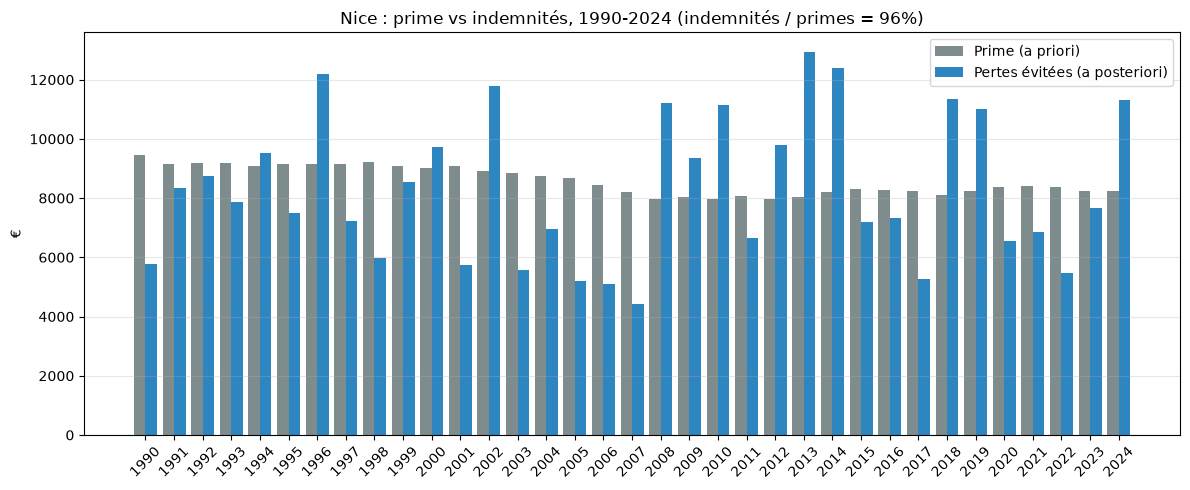

In [15]:
graphique_periode(periode)
plt.show()

In [16]:
print(f"Années favorables à l'assuré : {periode['favorable'].sum()} / {len(periode)}")
print(f"Indemnités versées / primes encaissées : {periode['pertes_evitees'].sum() / periode['P'].sum():.1%}")
print(f"Gain moyen de l'assuré par an : {periode['gain_assurance'].mean():,.0f} €")
print(f"Écart-type du résultat non assuré : {periode['R_nass'].std():,.0f} €")
print(f"Écart-type du résultat assuré net : {periode['R_net'].std():,.0f} €")

Années favorables à l'assuré : 13 / 35
Indemnités versées / primes encaissées : 96.3%
Gain moyen de l'assuré par an : -318 €
Écart-type du résultat non assuré : 12,221 €
Écart-type du résultat assuré net : 10,110 €


## 7. Sensibilité au niveau de pluie pivot

Même client, même année : comment la prime et le gain varient avec $\overline{pl}$.

In [17]:
histo = get_rainfall(client["ville"], f"{annee - n_annees_histo}-01-01", f"{annee - 1}-12-31")
lignes = []
for pivot in [2, 5, 10, 15, 20, 30]:
    r = backtest({**client, "pl_bar": pivot}, annee, pluie_annee=res["jours"], historique=histo)
    lignes.append({"pivot (mm)": pivot, "seuil (mm)": r["seuil"], "P": r["P"], "pertes évitées": r["pertes_evitees"],
                   "R_nass": r["R_nass"], "R_net": r["R_net"], "favorable": r["favorable"]})
sensi = pd.DataFrame(lignes)
sensi.style.format({"seuil (mm)": "{:.1f}", "P": "{:,.0f}", "pertes évitées": "{:,.0f}", "R_nass": "{:,.0f}", "R_net": "{:,.0f}"}).hide(axis="index")

pivot (mm),seuil (mm),P,pertes évitées,R_nass,R_net,favorable
2,1.4,"27,103","17,900","174,200","164,997",False
5,3.5,"16,156","11,700","196,880","192,424",False
10,7.0,"9,224","5,980","214,510","211,266",False
15,10.5,"6,025","3,913","223,627","221,515",False
20,14.0,"4,119","2,445","229,620","227,946",False
30,21.0,"2,055",900,"237,173","236,018",False


## 8. Conclusion

- La prime est une **prime pure** : en moyenne sur longue période, elle est proche des indemnités versées (ratio proche de 100 %). Elle est donc défavorable à l'assuré les années sèches et favorable les années pluvieuses.
- L'intérêt de l'assurance n'est pas de gagner de l'argent en moyenne, mais de **réduire la variabilité** du résultat annuel et de garantir $R_t \ge 0$ chaque jour.
- Avec un chargement de sécurité (module B), le ratio indemnités / primes passerait sous 100 %.
- La prime utilisée ici est provisoire (moyenne empirique à ± 15 jours) ; elle est remplacée automatiquement par `pricing.price` dès que le module B est ajouté au dépôt.